# 02 – Single-gene knockout screen

**Research question.** Which of the 1,515 metabolic genes in iML1515 does the model need for growth, and how does the answer change between a minimal and a rich medium?

**Biological motivation.** A gene is *essential* when the cell cannot grow without it. In a metabolic model this happens when deleting the gene blocks every route to at least one biomass component. Essentiality is conditional: a gene that only makes an amino acid is essential on glucose minimal medium but not in a medium that supplies the amino acid. Comparing two media separates core functions from biosynthetic ones.

**What this notebook does.**
- deletes every gene of iML1515 in turn and computes the growth rate of each knockout with FBA
- does this on two media: **glucose minimal** (the model default) and an **LB-like** rich medium
- decides when a knockout counts as *essential* and checks how much that decision depends on the threshold and on the LB uptake limit
- lists the genes that are essential only on minimal medium, grouped by pathway

**Expected outputs.**
- `results/tables/knockout_glucose_minimal.csv` and `knockout_lb_like.csv`: growth and essentiality call for every gene
- `results/tables/threshold_sensitivity.csv`, `lb_uptake_sensitivity.csv`, `predicted_essential_by_subsystem.csv`
- `results/figures/knockout_growth_ratio.png`, `predicted_essential_by_subsystem.png`
- headline numbers: 195 predicted essential genes on glucose minimal medium, 116 on LB-like medium

In a knockout simulation the gene is switched off, every reaction that can no longer be catalysed (according to its gene-reaction rule) is blocked, and FBA is asked again for the maximum growth rate.

The reusable code lives in `src/ecoli_fba/` (`media.py`, `knockout.py`, `annotation.py`); this notebook only calls it. Runtime: about two minutes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecoli_fba import RESULTS_DIR, annotation, knockout, media, plotting
from ecoli_fba.model import load_model

plotting.apply_style()
TABLES_DIR = RESULTS_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

model = load_model()
print(len(model.genes), "genes in the model, of which", len(model.genes) - 1, "are screened")
print("(s0001 is a placeholder gene for spontaneous reactions and is skipped)")

1516 genes in the model, of which 1515 are screened
(s0001 is a placeholder gene for spontaneous reactions and is skipped)


## 1. Two growth media

**Glucose minimal** is the medium the model ships with (notebook 01): glucose, oxygen, ammonium and inorganic salts.

**LB-like** adds the organic nutrients of a rich medium. LB is made from tryptone and yeast extract, so its exact composition is not defined; any in-silico LB is an approximation. Instead of inventing a list, the compound list is taken from the CarveMe media database (Machado et al. 2018), see `src/ecoli_fba/media.py`.

The two media bracket the question. On glucose minimal medium the cell must make every building block from glucose, ammonium and salts; on LB-like medium amino acids, nucleosides and several vitamins can be taken up instead.

In [2]:
glucose_medium = media.glucose_minimal_medium(model)
lb_medium, lb_missing = media.lb_like_medium(model, glucose_medium)

added = sorted(set(lb_medium) - set(glucose_medium))
print("Glucose minimal:", len(glucose_medium), "open exchange reactions")
print("LB-like:        ", len(lb_medium), "open exchange reactions")
print("LB compounds without an exchange reaction in iML1515 (cannot be supplied):", lb_missing)

pd.DataFrame(
    {
        "nutrient added by LB": [model.reactions.get_by_id(r).reactants[0].name for r in added],
        "max uptake (mmol/gDW/h)": [lb_medium[r] for r in added],
    },
    index=pd.Index(added, name="exchange reaction"),
)

Glucose minimal: 24 open exchange reactions
LB-like:         66 open exchange reactions
LB compounds without an exchange reaction in iML1515 (cannot be supplied): ['cro4', 'fol', 'ribflv']


,nutrient added by LB,max uptake (mmol/gDW/h)
exchange reaction,,
EX_adn_e,Adenosine,10.0
EX_ala__L_e,L-Alanine,10.0
EX_amp_e,AMP C10H12N5O7P,10.0
EX_arg__L_e,L-Arginine,10.0
EX_aso3_e,Arsenite,10.0
EX_asp__L_e,L-Aspartate,10.0
EX_cbl1_e,Cob(I)alamin,10.0
EX_cd2_e,Cadmium,10.0
EX_cmp_e,CMP C9H12N3O8P,10.0


In [3]:
wild_type = {}
for name, medium in [("glucose minimal", glucose_medium), ("LB-like", lb_medium)]:
    with model:
        media.apply_medium(model, medium)
        wild_type[name] = model.slim_optimize()

pd.Series(wild_type, name="wild-type growth rate (1/h)").round(3)

glucose minimal     0.877
LB-like            18.163
Name: wild-type growth rate (1/h), dtype: float64

**Caution about the LB-like growth rate.** Every added nutrient may be taken up at 10 mmol/gDW/h *at the same time*, which no real cell can do, so the absolute growth rate on LB-like medium is far above anything measured for *E. coli* and should not be read as a prediction. In this project the LB-like medium is only used for the yes/no question "can this knockout still grow?". Section 5 checks that the answer does not depend on the uptake limit.

## 2. Run the screens
Each screen solves one FBA problem per gene (about 15 s per medium).

For each gene, COBRApy evaluates every GPR rule with that gene absent. A reaction whose rule becomes false (for example `g1 and g2` without `g1`) is blocked; a reaction with an isozyme (`g1 or g2`) stays open. FBA then maximises biomass again. A knockout that cannot produce biomass at all is reported as zero growth.

In [4]:
gene_names = annotation.annotate_genes(model)[["gene_id", "gene_name"]]

screens = {}
for name, medium in [("glucose_minimal", glucose_medium), ("lb_like", lb_medium)]:
    with model:
        media.apply_medium(model, medium)
        result = knockout.run_knockouts(model)
    result["predicted_essential"] = knockout.classify_essential(result["growth_ratio"])
    result = gene_names.merge(result, on="gene_id")
    result.round({"growth": 6, "growth_ratio": 6}).to_csv(TABLES_DIR / f"knockout_{name}.csv", index=False)
    screens[name] = result

screens["glucose_minimal"].head()

,gene_id,gene_name,growth,growth_ratio,status,predicted_essential
0,b2551,glyA,0.865637,0.987046,optimal,False
1,b0870,ltaE,0.876995,0.999997,optimal,False
2,b3368,cysG,0.000000,0.000000,optimal,True
3,b2436,hemF,0.876962,0.999960,optimal,False
4,b0008,talB,0.876997,1.000000,optimal,False


## 3. How well do the knockouts grow?
`growth_ratio` is the knockout growth rate divided by the wild-type growth rate on the same medium (0 = no growth, 1 = unaffected). The y-axis is logarithmic because most knockouts sit at exactly 0 or 1.

A ratio near 1 means the network has an equally good alternative. Intermediate values mean the model can reroute flux, at a cost in biomass yield.

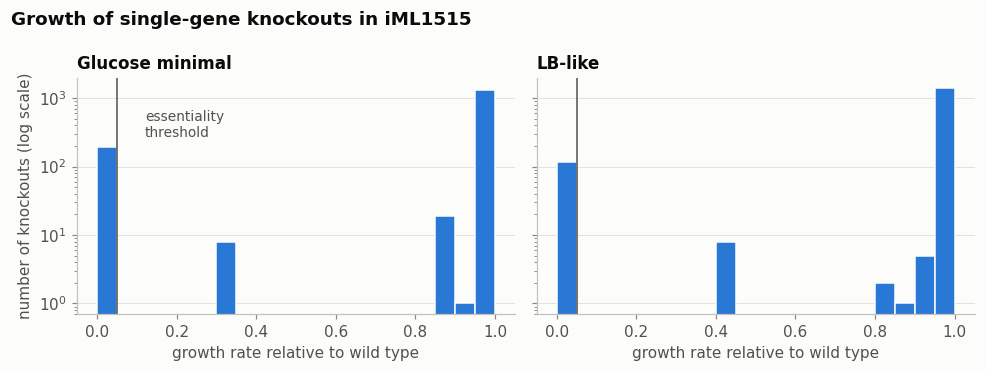

In [5]:
titles = {"glucose_minimal": "Glucose minimal", "lb_like": "LB-like"}
bins = np.linspace(0, 1, 21)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (name, result) in zip(axes, screens.items()):
    ax.hist(result["growth_ratio"].clip(upper=1), bins=bins, color=plotting.BLUE)
    ax.axvline(knockout.DEFAULT_THRESHOLD, color=plotting.INK_SECONDARY, linewidth=1)
    ax.set_yscale("log")
    ax.set_title(titles[name])
    ax.set_xlabel("growth rate relative to wild type")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of knockouts (log scale)")
axes[0].annotate(
    "essentiality\nthreshold", xy=(knockout.DEFAULT_THRESHOLD, 400), xytext=(0.12, 400),
    color=plotting.INK_SECONDARY, va="center", fontsize=9,
)
fig.suptitle("Growth of single-gene knockouts in iML1515", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_figure(fig, "knockout_growth_ratio")
plt.show()

In [6]:
def growth_classes(ratio):
    return pd.Series(
        {
            "no growth (ratio < 0.05)": int((ratio < 0.05).sum()),
            "reduced growth (0.05 to 0.99)": int(((ratio >= 0.05) & (ratio < 0.99)).sum()),
            "unaffected (ratio >= 0.99)": int((ratio >= 0.99).sum()),
        }
    )

pd.DataFrame({titles[name]: growth_classes(result["growth_ratio"]) for name, result in screens.items()})

,Glucose minimal,LB-like
no growth (ratio < 0.05),195,116
reduced growth (0.05 to 0.99),48,43
unaffected (ratio >= 0.99),1272,1356


## 4. Choosing the essentiality threshold
A knockout is called **essential** when its growth ratio is below a threshold. There is no single agreed value, so the table shows how many genes would be called essential for a range of thresholds. The project default is 0.05 (`knockout.DEFAULT_THRESHOLD`).

In [7]:
thresholds = [1e-6, 0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 0.9]
sensitivity = pd.DataFrame(
    {
        titles[name]: knockout.threshold_sensitivity(result["growth_ratio"], thresholds)
        .set_index("threshold")["n_essential"]
        for name, result in screens.items()
    }
)
sensitivity.to_csv(TABLES_DIR / "threshold_sensitivity.csv")
sensitivity

,Glucose minimal,LB-like
threshold,,
0.000001,195,116
0.001000,195,116
0.010000,195,116
0.050000,195,116
0.100000,195,116
0.200000,195,116
0.500000,203,124
0.900000,222,127


## 5. Does the LB uptake limit change the result?
The uptake limit of the nutrients added by LB (10 mmol/gDW/h) is an arbitrary choice. The screen is repeated with a 10x lower and a 10x higher limit and the set of essential genes is compared with the default.

In [8]:
default_essential = set(screens["lb_like"].query("predicted_essential")["gene_id"])

rows = []
for uptake in [1.0, 10.0, 100.0]:
    medium, _ = media.lb_like_medium(model, glucose_medium, uptake=uptake)
    with model:
        media.apply_medium(model, medium)
        wt = model.slim_optimize()
        result = knockout.run_knockouts(model)
    essential = set(result.loc[knockout.classify_essential(result["growth_ratio"]), "gene_id"])
    rows.append(
        {
            "uptake limit": uptake,
            "wild-type growth (1/h)": round(wt, 2),
            "essential genes": len(essential),
            "calls that differ from default": len(essential ^ default_essential),
        }
    )

lb_uptake_sensitivity = pd.DataFrame(rows).set_index("uptake limit")
lb_uptake_sensitivity.to_csv(TABLES_DIR / "lb_uptake_sensitivity.csv")
lb_uptake_sensitivity

,wild-type growth (1/h),essential genes,calls that differ from default
uptake limit,,,
1.0,3.38,116,0
10.0,18.16,116,0
100.0,53.99,116,0


## 6. Genes that are essential only on minimal medium
Comparing the two screens separates genes the model needs on both media from genes it needs only when the cell has to make everything from glucose.

Knockouts that are essential only on minimal medium are **auxotrophs** in the model: they grow again once the missing end product (an amino acid, a nucleotide, a vitamin) is supplied.

In [9]:
essential_glucose = set(screens["glucose_minimal"].query("predicted_essential")["gene_id"])
essential_lb = set(screens["lb_like"].query("predicted_essential")["gene_id"])

both = essential_glucose & essential_lb
only_glucose = essential_glucose - essential_lb
only_lb = essential_lb - essential_glucose

pd.Series(
    {
        "essential on both media": len(both),
        "essential only on glucose minimal": len(only_glucose),
        "essential only on LB-like": len(only_lb),
        "not essential on either": len(screens["lb_like"]) - len(essential_glucose | essential_lb),
    },
    name="number of genes",
)

essential on both media               116
essential only on glucose minimal      79
essential only on LB-like               0
not essential on either              1320
Name: number of genes, dtype: int64

In [10]:
by_subsystem = pd.DataFrame(
    {
        "essential on both media": annotation.count_by_subsystem(annotation.annotate_genes(model, sorted(both))),
        "essential only on glucose minimal": annotation.count_by_subsystem(annotation.annotate_genes(model, sorted(only_glucose))),
    }
).fillna(0).astype(int)
by_subsystem["total"] = by_subsystem.sum(axis=1)
by_subsystem = by_subsystem.sort_values("total", ascending=False)
by_subsystem.to_csv(TABLES_DIR / "predicted_essential_by_subsystem.csv")
by_subsystem.head(15)

,essential on both media,essential only on glucose minimal,total
subsystem,,,
Cofactor and Prosthetic Group Biosynthesis,53,20,73
Lipopolysaccharide Biosynthesis / Recycling,19,0,19
Cell Envelope Biosynthesis,17,0,17
Purine and Pyrimidine Biosynthesis,0,16,16
"Tyrosine, Tryptophan, and Phenylalanine Metabolism",4,8,12
Arginine and Proline Metabolism,1,9,10
Threonine and Lysine Metabolism,6,3,9
Membrane Lipid Metabolism,8,0,8
Cysteine Metabolism,0,8,8


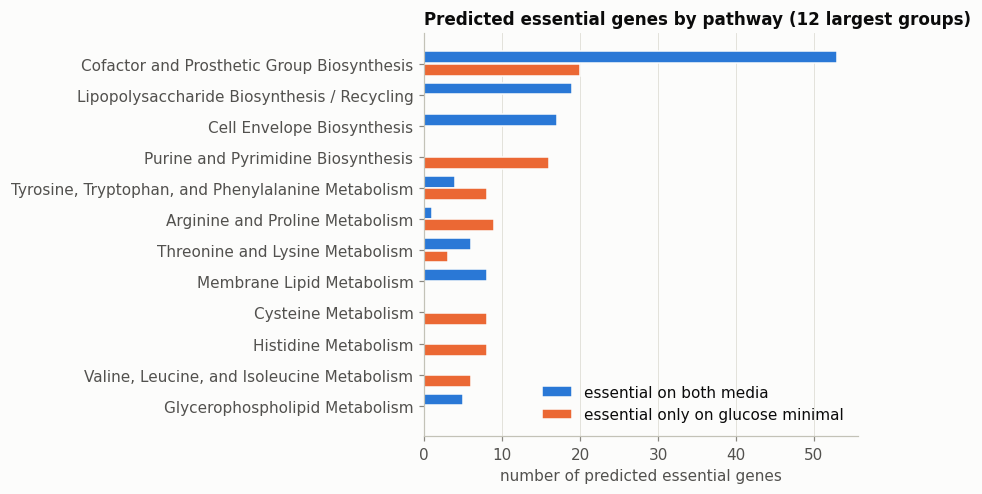

In [11]:
top = by_subsystem.head(12).iloc[::-1]
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(y + 0.2, top["essential on both media"], height=0.38, color=plotting.BLUE, label="essential on both media")
ax.barh(y - 0.2, top["essential only on glucose minimal"], height=0.38, color=plotting.ORANGE, label="essential only on glucose minimal")
ax.set_yticks(y, top.index)
ax.set_xlabel("number of predicted essential genes")
ax.set_title("Predicted essential genes by pathway (12 largest groups)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
plotting.save_figure(fig, "predicted_essential_by_subsystem")
plt.show()

A gene whose reactions belong to several pathways is counted once in each of them, so the bars add up to more than the number of genes.

**Questions and answers**

1. *Why are most knockouts either at 0 or at 1, with so few in between? What does that say about how FBA treats a deleted gene?*
   FBA only asks whether a stoichiometrically feasible route exists and how much biomass it yields. A deletion either removes the only route to at least one biomass component (growth 0) or the network contains an isoenzyme or a parallel pathway with the same yield (growth 1). Using an alternative costs nothing in the model, because enzyme amounts, kinetics and regulation are not represented. Intermediate values appear only when the detour has a lower yield, as for the eight ATP synthase subunits (0.325 on glucose minimal medium), whose knockouts must make ATP without oxidative phosphorylation. On glucose minimal medium 195 knockouts are below 0.05, 48 between 0.05 and 0.99 and 1,272 at 0.99 or above.

2. *The number of essential genes barely changes between a threshold of 0.000001 and 0.2. Why is the choice of threshold still worth reporting?*
   Reporting it shows that the calls are not an artefact of the chosen value, and it makes the results comparable with studies that use other thresholds. It also shows where the choice would matter: at 0.5 the counts rise from 195 to 203 (glucose minimal) and from 116 to 124 (LB-like), the eight ATP synthase subunits, and at 0.9 to 222 and 127.

3. *Which pathways contain the genes that are essential only on glucose minimal medium? Is that what you expected, and why?*
   Cofactor biosynthesis (20 genes), purine and pyrimidine biosynthesis (16), arginine and proline (9), aromatic amino acids (8), cysteine (8), histidine (8), branched-chain amino acids (6), threonine and lysine (3), methionine (2) and the citric acid cycle (2: *gltA*, *icd*). This is the pattern expected from auxotrophy: on minimal medium the cell must make every amino acid, nucleotide and cofactor from glucose, whereas the LB-like medium supplies them. The two citric acid cycle genes fit as well: citrate synthase and isocitrate dehydrogenase lead to 2-oxoglutarate, the precursor of glutamate, which the LB-like medium provides.

4. *The LB-like wild-type growth rate is unrealistically high. Why does this not affect the essential / non-essential calls?*
   Each knockout is judged relative to the wild type on the same medium, and whether a knockout can grow at all depends on whether a route to every biomass component exists, not on how fast nutrients are taken up. Section 5 confirms this: with uptake limits of 1, 10 and 100 mmol/gDW/h the wild-type rate changes from 3.38 to 18.16 to 53.99 h⁻¹, but the same 116 genes are essential every time.

## Notes

**Observations**
- No gene is essential only on the LB-like medium. This is expected: the LB-like medium is the glucose minimal medium plus extra nutrients, and opening exchange reactions can only enlarge the set of feasible flux distributions.
- The ATP synthase subunits are the only cluster of knockouts with intermediate growth (0.325 on glucose minimal, 0.405 on LB-like medium).
- Three of the 65 published LB compounds (chromate, folate, riboflavin) have no exchange reaction in iML1515 and cannot be supplied.

**To check next**
- Do the 79 genes that are essential only on glucose minimal medium correspond to Keio mutants that grow in LB but not in glucose MOPS medium?

Next notebook: compare these predictions with the Keio collection.